# 09. Evaluación y comparación de protocolos

Comparar exclusivamente los resultados existentes de StandardScaler y MinMaxScaler.

**Dataset principal:** `data/nuevo_dataset/cardio_train.csv`. Este cuaderno no ejecuta entrenamientos. Los resultados históricos se leen de archivos conservados; no se sustituyen por nuevas ejecuciones.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data/nuevo_dataset/cardio_train.csv").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from src.experimento import (
    ORIGINAL, RESULTADOS, VARIABLES, NOMBRES, cargar_datos, reglas_calidad,
    cargar_metricas, comparar_ejecuciones, tabla_configuracion, verificar_configuracion,
    construir_cnn, tabla_modelo, dibujar_arquitectura, guardar_figura_nueva,
    importancia_guardada, resumen_dataset, verificar_predicciones, tensorflow_disponible,
)

09_evaluacion_comparacion:celda-2:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


,Protocolo,Entrenamiento,Validación,Prueba,Épocas,Parámetros,Accuracy,Precision,Recall,F1,ROC-AUC
0,StandardScaler,10500,2250,2250,44,34529,0.712444,0.716141,0.693621,0.704701,0.775738
1,MinMaxScaler,10200,2550,2250,66,34529,0.731111,0.732601,0.718778,0.725624,0.788458


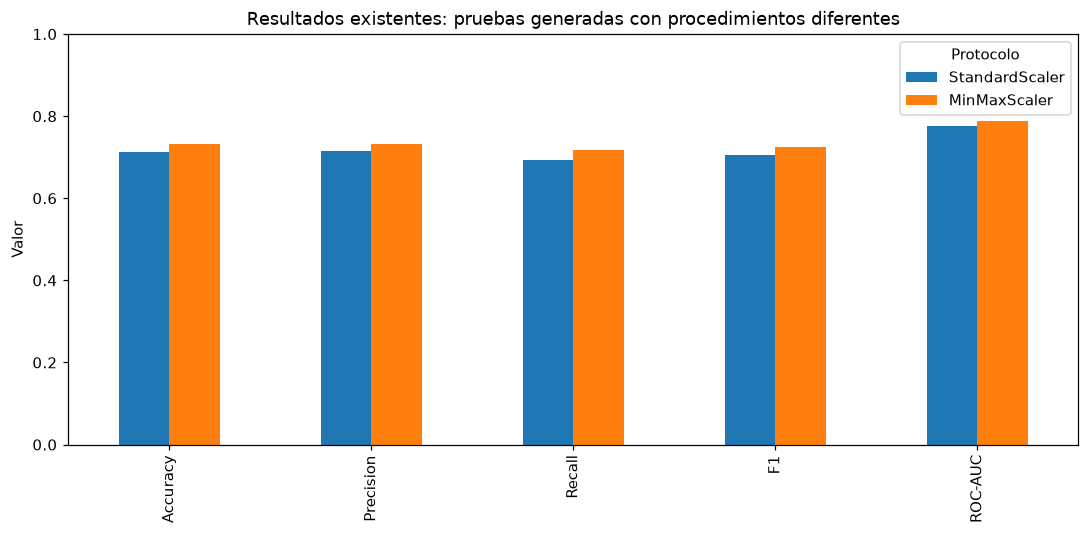

In [2]:
comparacion = comparar_ejecuciones()
display(comparacion)
fig, ax = plt.subplots(figsize=(10, 5))
comparacion.set_index("Protocolo")[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]].T.plot.bar(ax=ax)
ax.set_ylim(0, 1)
ax.set_ylabel("Valor")
ax.set_title("Resultados existentes: pruebas generadas con procedimientos diferentes")
fig.tight_layout()
plt.show()

Ambas ejecuciones tienen 34,529 parámetros. Cambian escalador, particiones y validación, paciencia y número de épocas. La diferencia de resultados es descriptiva: no demuestra que MinMaxScaler sea superior por sí solo ni que cambió la arquitectura. No se efectuó una comparación controlada con un mismo test, varias semillas o intervalos de confianza. La limitación del escalamiento previo a la reserva de validación se conserva explícitamente.

In [3]:
verificadas, matriz = verificar_predicciones()
display(verificadas)
print("Matriz definitiva:", matriz.tolist())

Matriz definitiva: [[845, 292], [313, 800]]


,Metrica,Valor
0,Accuracy,0.731111
1,Precision,0.732601
2,Recall,0.718778
3,F1-score,0.725624
4,ROC-AUC,0.788458
